# Difference-in-differences

When treatment is not randomised but outcomes are observed before and after it, the
difference-in-differences design compares outcome *changes* of treated and untreated units.
dml-rs implements the doubly robust DiD estimators of Sant'Anna and Zhao (2020), for panels and
repeated cross-sections, and staggered adoption (Callaway and Sant'Anna, 2021), as in DoubleML.
Parallel trends only need to hold conditional on covariates $X$.

In [1]:
import warnings

import numpy as np
import pandas as pd

import dml_rs

warnings.filterwarnings("ignore", category=FutureWarning)  # scikit-learn deprecation notices
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by DoubleML
pd.set_option("display.precision", 4)

## Two periods, panel data

Units with high $X_1$ are more likely to be treated *and* have a steeper trend, so a plain
comparison of outcome changes is biased. The true effect on the treated is 2.

In [2]:
rng = np.random.default_rng(3)
n = 3000
X = rng.normal(size=(n, 5))
d = rng.binomial(1, 1 / (1 + np.exp(-X[:, 0]))).astype(float)
trend = 1 + X[:, 0] + 0.5 * X[:, 1]
y0 = 5 + X[:, 0] + rng.normal(size=n)           # pre-period outcome
y1 = y0 + trend + 2 * d + rng.normal(size=n)    # post-period outcome
dy = y1 - y0                                    # DID uses each unit's change

print(f"naive comparison of changes: {dy[d == 1].mean() - dy[d == 0].mean():.3f}")

naive comparison of changes: 2.887


In [3]:
did = dml_rs.DID(ml_g=dml_rs.LassoCV(), ml_m=dml_rs.LogisticRegressionCV()).fit(X, dy, d)
did.summary

,coef,std err,t,P>|t|,2.5 %,97.5 %
d,2.0678,0.0452,45.7723,0.0,1.9792,2.1563


## Repeated cross-sections

If different units are sampled before and after, `DIDCS` takes the outcome levels and a
post-period indicator `t`:

In [4]:
t = rng.binomial(1, 0.5, size=n).astype(float)
y_cs = 5 + X[:, 0] + t * trend + 2 * d * t + rng.normal(size=n)
did_cs = dml_rs.DIDCS(dml_rs.LassoCV(), dml_rs.LogisticRegressionCV()).fit(X, y_cs, d, t)
did_cs.summary

,coef,std err,t,P>|t|,2.5 %,97.5 %
d,2.125,0.0908,23.4075,3.5869e-121,1.9471,2.3029


## Staggered adoption

With several cohorts treated at different times, `StaggeredDID` estimates every group-time effect
$\text{ATT}(g, t)$ and aggregates them by cohort, calendar time or event time. The data below come
from DoubleML's simulator for Callaway and Sant'Anna (2021): `d` is the first treated period
(`inf` for never treated) and the true potential outcomes `y0`, `y1` are known.

In [5]:
from doubleml.did.datasets import make_did_CS2021

np.random.seed(11)
df = make_did_CS2021(n_obs=2000, dgp_type=1, include_never_treated=True, time_type="float")
x_cols = ["Z1", "Z2", "Z3", "Z4"]
df.head()

,id,y,y0,y1,d,t,Z1,Z2,Z3,Z4
0,0,214.1636,214.1636,213.6892,2.0,0,2.0656,-0.0981,-0.8407,-1.9611
1,0,217.8264,217.8264,217.4264,2.0,1,2.0656,-0.0981,-0.8407,-1.9611
2,0,222.9586,220.9318,222.9586,2.0,2,2.0656,-0.0981,-0.8407,-1.9611
3,0,231.0651,226.6774,231.0651,2.0,3,2.0656,-0.0981,-0.8407,-1.9611
4,0,235.0303,233.2738,235.0303,2.0,4,2.0656,-0.0981,-0.8407,-1.9611


In [6]:
staggered = dml_rs.StaggeredDID(dml_rs.LassoCV(), dml_rs.LogisticRegressionCV())
staggered.fit_frame(df, y_col="y", id_col="id", t_col="t", g_col="d", x_cols=x_cols)
staggered.summary.head(8)

,coef,std err,t,P>|t|,2.5 %,97.5 %
"ATT(2,0,1)",0.0026,0.0892,0.0290,9.7690e-01,-0.1722,0.1774
"ATT(2,1,2)",0.8337,0.0917,9.0928,9.6548e-20,0.6540,1.0134
"ATT(2,1,3)",1.9593,0.0898,21.8183,1.5555e-105,1.7833,2.1353
"ATT(2,1,4)",2.9664,0.0923,32.1504,8.7094e-227,2.7856,3.1473
"ATT(3,0,1)",0.1071,0.0918,1.1662,2.4351e-01,-0.0729,0.2871
"ATT(3,1,2)",-0.0608,0.0958,-0.6351,5.2534e-01,-0.2485,0.1269
"ATT(3,2,3)",1.0056,0.0902,11.1469,7.4143e-29,0.8287,1.1824
"ATT(3,2,4)",1.9752,0.0931,21.2275,5.3216e-100,1.7928,2.1576


The event-study aggregation averages the effects by time since treatment. Its estimates track the
true effects, which we can compute here from the simulated potential outcomes:

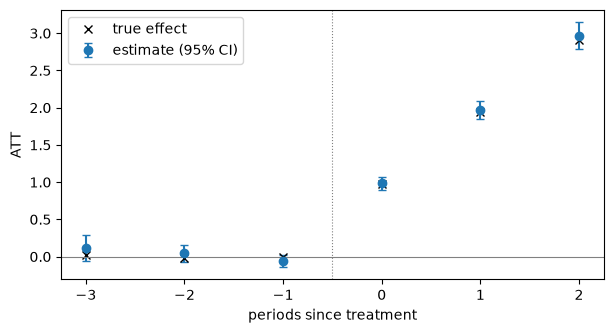

In [7]:
import matplotlib.pyplot as plt

event = staggered.aggregate("eventstudy")
ci = event.confint()
e = np.asarray(event.names, dtype=float)

treated = df[np.isfinite(df["d"])]
truth = (treated["y1"] - treated["y0"]).groupby(treated["t"] - treated["d"]).mean()
truth = truth[truth.index.isin(e)]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(e, event.coef, yerr=[event.coef - ci[:, 0], ci[:, 1] - event.coef],
            fmt="o", capsize=3, label="estimate (95% CI)")
ax.plot(truth.index, truth.values, "x", color="black", label="true effect")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(-0.5, color="grey", lw=0.8, ls=":")
ax.set_xlabel("periods since treatment")
ax.set_ylabel("ATT")
ax.legend()
plt.show()

In [8]:
event.overall_summary

,coef,std err,t,P>|t|,2.5 %,97.5 %
overall,1.9728,0.0559,35.3078,4.4567e-273,1.8632,2.0823
